In [2]:
import pandas as pd
import numpy as np
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import os
import joblib

SEED=42

In [3]:
raw_df = pd.read_csv("ecommerce_customer_reviews_2026.csv")
raw_df.columns = raw_df.columns.str.strip()

In [4]:
core_cols = ['Review_ID','Product_Category','Review_Title','Review_Text','Star_Rating','Quality_Sentiment','Shipping_Sentiment','Emotion',
'Verified_Purchase','Is_Repeat_Customer','Return_Mentioned','Complaint_Mentioned','Is_Potentially_Fake','Fake_Review_Score']

In [5]:
cleaned_df = raw_df[core_cols].dropna(subset=['Review_Text', 'Star_Rating']).copy()
df_sample = cleaned_df.sample(n=5000, random_state=SEED).reset_index(drop=True)

In [6]:
df_sample['Review_Title']=df_sample['Review_Title'].fillna('')
df_sample['Full_Review'] = (df_sample['Review_Title'] + " " + df_sample['Review_Text']).str.lower()

In [7]:
print(df_sample['Quality_Sentiment'].value_counts(dropna=False))

Quality_Sentiment
Not Mentioned    4306
Positive          347
Negative          302
Neutral            45
Name: count, dtype: int64


In [8]:
sentiment_map = {
    'Positive': 1.0,
    'Neutral': 0.5,
    'Negative': 0.0
}

In [9]:
df_sample['Quality_Sentiment_Num'] = pd.to_numeric(df_sample['Quality_Sentiment'].map(sentiment_map), errors='coerce').fillna(0.5)

In [10]:
normalized_rating = pd.to_numeric(df_sample['Star_Rating'], errors='coerce') / 5.0
df_sample['Rating_Quality_Mismatch'] = np.abs(normalized_rating - df_sample['Quality_Sentiment_Num'])

In [11]:
shrinkage_terms = r'\b(empty|missing|stolen|tampered|unsealed|swapped|used|fake|broken|tape)\b'
df_sample['Shrinkage_Keyword_Flag'] = df_sample['Full_Review'].apply(lambda text: 1 if re.search(shrinkage_terms, str(text)) else 0)

print("Mismatch and Shrinkage flags created successfully!")

Mismatch and Shrinkage flags created successfully!


In [12]:
vectorizer = TfidfVectorizer(max_features=500, stop_words='english')
tfidf_matrix = vectorizer.fit_transform(df_sample['Full_Review'])

In [13]:
pca = PCA(n_components=2, random_state=SEED)
pca_vectors = pca.fit_transform(tfidf_matrix.toarray())
df_sample['Text_PCA1'] = pca_vectors[:, 0]
df_sample['Text_PCA2'] = pca_vectors[:, 1]

In [14]:
df_final = pd.get_dummies(df_sample, columns=['Product_Category', 'Emotion'], drop_first=True)
df_final.to_csv('cleaned_retail_shrinkage.csv', index=False)

print(f"Success! Processed dataset saved with shape: {df_final.shape}")

Success! Processed dataset saved with shape: (5000, 41)


Model Implementation

In [15]:
from sklearn.ensemble import IsolationForest
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns

SEED=42

In [16]:
meta_cols = ['Review_ID', 'Review_Title', 'Review_Text', 'Full_Review', 'Quality_Sentiment', 'Shipping_Sentiment']
X_unscaled = df_sample.select_dtypes(include=[np.number, bool]).copy()
X_unscaled = X_unscaled.astype(float)

scaler = StandardScaler()
X = scaler.fit_transform(X_unscaled) 

print(f"Feature matrix ready for training! Scaled matrix shape: {X.shape}")

Feature matrix ready for training! Scaled matrix shape: (5000, 12)


In [17]:
non_numeric_cols = X_unscaled.select_dtypes(include=['object', 'category', 'string']).columns.tolist()
print("Non-numeric columns found in X:", non_numeric_cols)

Non-numeric columns found in X: []


In [18]:
iso_forest = IsolationForest(contamination=0.05, random_state=SEED, n_jobs=-1)
df_sample['Anomaly_Flag'] = iso_forest.fit_predict(X)

In [19]:
df_sample['Is_Shrinkage_Anomaly'] = df_sample['Anomaly_Flag'].apply(lambda x: 1 if x == -1 else 0)
df_sample['Anomaly_Score'] = iso_forest.decision_function(X)

In [20]:
print(f"Detected Anomalies: {df_sample['Is_Shrinkage_Anomaly'].sum()} / {len(df_sample)}")

Detected Anomalies: 250 / 5000


In [21]:
anomalies_X = X[df_sample['Is_Shrinkage_Anomaly'] == 1]

kmeans = KMeans(n_clusters=3, random_state=SEED, n_init=10)
df_sample.loc[df_sample['Is_Shrinkage_Anomaly'] == 1, 'Shrinkage_Cluster'] = kmeans.fit_predict(anomalies_X)

In [22]:
sil_score = silhouette_score(anomalies_X, kmeans.labels_)
print(f"Anomaly Cluster Silhouette Score: {sil_score:.4f}")

Anomaly Cluster Silhouette Score: 0.4556


In [23]:
df_sample.to_csv('model_outputs_retail_shrinkage.csv', index=False)
print("Saved final model outputs to 'model_outputs_retail_shrinkage.csv'")

Saved final model outputs to 'model_outputs_retail_shrinkage.csv'


In [24]:
anomaly_df = df_sample[df_sample['Is_Shrinkage_Anomaly'] == 1].copy()

In [25]:
cluster_profile = anomaly_df.groupby('Shrinkage_Cluster')[['Rating_Quality_Mismatch', 'Shrinkage_Keyword_Flag',
    'Fake_Review_Score', 'Is_Potentially_Fake', 'Star_Rating']].mean().reset_index()

In [26]:
print("--Anomaly Cluster Profiles--")
print(cluster_profile)

--Anomaly Cluster Profiles--
   Shrinkage_Cluster  Rating_Quality_Mismatch  Shrinkage_Keyword_Flag  \
0                0.0                 0.018605                     0.0   
1                1.0                 0.308081                     0.0   
2                2.0                 0.350769                     0.0   

   Fake_Review_Score  Is_Potentially_Fake  Star_Rating  
0           0.422448                  0.0     4.906977  
1           0.439903                  0.0     1.484848  
2           0.178417                  0.0     1.753846  


In [27]:
for cluster in sorted(anomaly_df['Shrinkage_Cluster'].unique()):
    print(f"\n--- Cluster {int(cluster)} Sample Reviews ---")
    samples = anomaly_df[anomaly_df['Shrinkage_Cluster'] == cluster][['Review_Title', 'Review_Text']].head(3)
    for idx, row in samples.iterrows():
        print(f"Title: {row['Review_Title']}")
        print(f"Text : {row['Review_Text']}\n")


--- Cluster 0 Sample Reviews ---
Title: Highly Recommended!
Text : I love this electronics product! The quality is excellent. Satisfied!

Title: Great Quality!
Text : Great furniture product! The quality is amazing. Great value!

Title: Highly Recommended!
Text : I love this office product! The quality is excellent. Great value!


--- Cluster 1 Sample Reviews ---
Title: Poor Quality
Text : Poor quality fashion product. Not recommended. Avoid this.

Title: Not Worth It
Text : Poor quality pets product. Not recommended. Disappointed.

Title: Poor Quality
Text : Poor quality phones product. Not recommended. Waste of money.


--- Cluster 2 Sample Reviews ---
Title: Not Worth It
Text : Disappointed with this office product. The quality is poor. Avoid this.

Title: Not Worth It
Text : Disappointed with this computers product. The quality is poor. Waste of money.

Title: Disappointed
Text : Poor quality computers product. Not recommended. Not worth it.



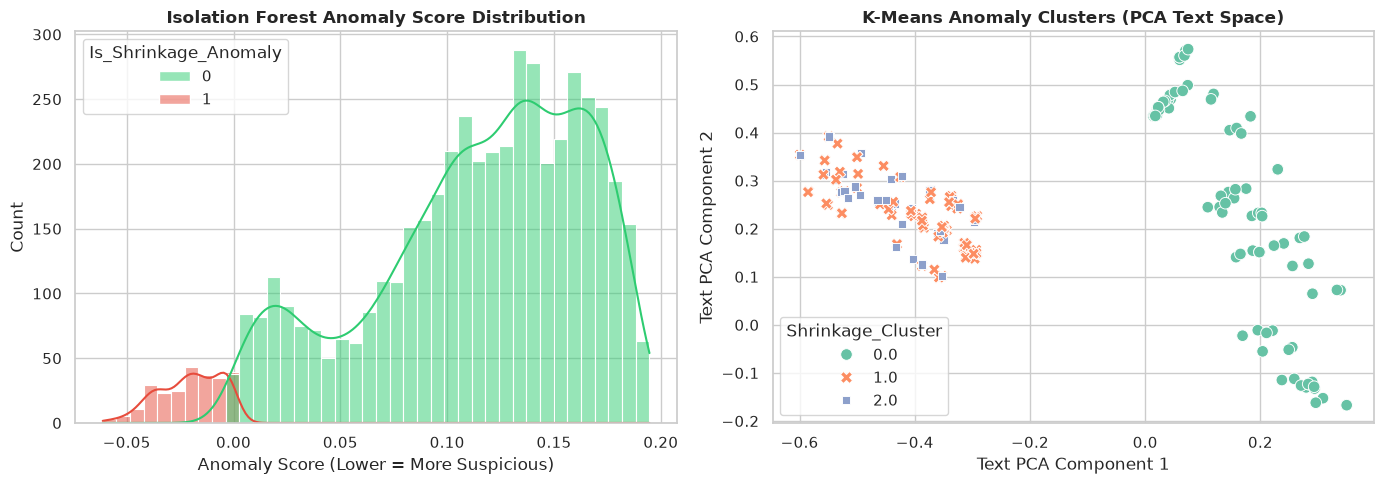

Plots successfully generated and saved to 'shrinkage_anomaly_clusters.png'


In [28]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df_sample, x='Anomaly_Score', hue='Is_Shrinkage_Anomaly', bins=40, kde=True, ax=axes[0], palette={0: "#2ecc71", 1: '#e74c3c'})
axes[0].set_title('Isolation Forest Anomaly Score Distribution', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Anomaly Score (Lower = More Suspicious)')

anomaly_data = df_sample[df_sample['Is_Shrinkage_Anomaly'] == 1]
sns.scatterplot(data=anomaly_data, x='Text_PCA1', y='Text_PCA2', hue='Shrinkage_Cluster', palette='Set2', style='Shrinkage_Cluster', s=70, ax=axes[1])
axes[1].set_title('K-Means Anomaly Clusters (PCA Text Space)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Text PCA Component 1')
axes[1].set_ylabel('Text PCA Component 2')

plt.tight_layout()
plt.savefig('shrinkage_anomaly_clusters.png', dpi=300)
plt.show()

print("Plots successfully generated and saved to 'shrinkage_anomaly_clusters.png'")

In [29]:
cluster_names = {0.0: 'Value/Quality Dissatisfaction',1.0: 'Rating Mismatch / Suspected Fake',2.0: 'Standard Product Return Risk'}
df_sample['Shrinkage_Cluster_Label'] = df_sample['Shrinkage_Cluster'].map(cluster_names)

In [30]:
summary_table = df_sample[df_sample['Is_Shrinkage_Anomaly'] == 1].groupby('Shrinkage_Cluster_Label').agg(Total_Cases=('Review_ID', 'count'),Avg_Star_Rating=('Star_Rating', 'mean'),
    Avg_Mismatch_Score=('Rating_Quality_Mismatch', 'mean'),Shrinkage_Keyword_Hits=('Shrinkage_Keyword_Flag', 'sum')).reset_index()

In [31]:
print("--Executive Shrinkage Risk Summary--")
print(summary_table)

--Executive Shrinkage Risk Summary--
            Shrinkage_Cluster_Label  Total_Cases  Avg_Star_Rating  \
0  Rating Mismatch / Suspected Fake           99         1.484848   
1      Standard Product Return Risk           65         1.753846   
2     Value/Quality Dissatisfaction           86         4.906977   

   Avg_Mismatch_Score  Shrinkage_Keyword_Hits  
0            0.308081                       0  
1            0.350769                       0  
2            0.018605                       0  


In [32]:
df_sample.to_csv('final_shrinkage_anomaly_report.csv', index=False)
print("Output saved to 'final_shrinkage_anomaly_report.csv'.")

Output saved to 'final_shrinkage_anomaly_report.csv'.


User Input

In [33]:
os.makedirs('models', exist_ok=True)

In [34]:
joblib.dump(iso_forest, 'models/isolation_forest_model.pkl')
joblib.dump(kmeans, 'models/kmeans_cluster_model.pkl')
joblib.dump(vectorizer, 'models/tfidf_vectorizer.pkl')
joblib.dump(pca, 'models/pca_transformer.pkl')
joblib.dump(scaler, 'models/scaler.pkl')

print("All models successfully serialized to 'models/' directory!")

All models successfully serialized to 'models/' directory!
